# EDA: прогноз установившегося режима сети (35 узлов, 80 линий)

**Как пользоваться:** положите `train_nodes_34_100000.csv` и `train_lines_34_100000.csv` рядом с ноутбуком
(или поправьте пути в первой ячейке) и запускайте ячейки сверху вниз.

План:
1. Загрузка и структура данных
2. Флаг `regime_valid` (сходимость)
3. Узлы: типы узлов, нагрузки, генерация, баланс
4. Что отличает сходящиеся режимы от несходящихся
5. Целевые переменные: `V`, `Delta`
6. Линии: топология, параметры, токи
7. Физическая проверка токов по закону Ома
8. Оценка бейзлайна организаторов (опционально)

## 0. Настройки

In [3]:
import warnings, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
plt.rcParams["figure.figsize"] = (10, 4)

DATA_DIR = Path(".")
NODES_PATH = DATA_DIR / "train_nodes_34_100000.csv"
LINES_PATH = DATA_DIR / "train_lines_34_100000.csv"

# Для быстрой отладки можно взять только первые N режимов, например 20000. None = все 100000.
SAMPLE_EXPS = None

# Названия столбцов как в файлах -> короткие внутренние имена
NODE_MAP = {"ID_опыта": "exp", "Номер": "num", "U_ном": "U", "P_н": "Pn", "Q_н": "Qn",
            "P_г": "Pg", "V": "V", "Delta": "Delta", "regime_valid": "valid"}
LINE_MAP = {"ID_опыта": "exp", "Номер": "num", "N_s": "Ns", "N_e": "Ne", "type": "type",
            "R": "R", "X": "X", "B": "B", "Kt": "Kt", "I_max": "Imax", "I_доп": "Idop", "I_zarg": "Izarg"}

## 1. Загрузка и структура

In [5]:
def load(path, mapping):
    df = pd.read_csv(path)
    missing = set(mapping) - set(df.columns)
    if missing:
        raise ValueError(f"В {path.name} нет столбцов {missing}. Есть: {list(df.columns)}")
    df = df.rename(columns=mapping)
    for c in df.select_dtypes("float64").columns:
        df[c] = df[c].astype("float32")      # экономим память
    for c in df.select_dtypes("int64").columns:
        df[c] = df[c].astype("int32")
    return df

nodes = load(NODES_PATH, NODE_MAP)
lines = load(LINES_PATH, LINE_MAP)

if SAMPLE_EXPS:
    keep = np.sort(nodes["exp"].unique())[:SAMPLE_EXPS]
    nodes = nodes[nodes["exp"].isin(keep)].reset_index(drop=True)
    lines = lines[lines["exp"].isin(keep)].reset_index(drop=True)

print("nodes:", nodes.shape, "| lines:", lines.shape)
print(f"память: nodes {nodes.memory_usage().sum()/1e6:.0f} МБ, lines {lines.memory_usage().sum()/1e6:.0f} МБ")
display(nodes.head(3)); display(lines.head(3))

nodes: (3500000, 9) | lines: (8000000, 12)
память: nodes 126 МБ, lines 384 МБ


,exp,num,U,Pn,Qn,Pg,V,Delta,valid
0,1,1,500.0,0.0,0.0,0.0,510.000000,-17.385,1
1,1,2,500.0,0.0,0.0,0.0,510.000000,-10.669,1
2,1,3,500.0,0.0,0.0,0.0,506.709015,-10.530,1


,exp,num,Ns,Ne,type,R,X,B,Kt,Imax,Idop,Izarg
0,1,1,999,3,0,2.96,45.599998,-546.799988,0.0,1177.199951,3003.100098,39.200001
1,1,2,999,4,0,1.18,18.240000,-218.699997,0.0,876.900024,3003.100098,29.200001
2,1,3,15,16,0,1.10,6.300000,-40.500000,0.0,632.700012,824.900024,76.699997


In [25]:
# Убираем пробелы в начале и конце названий всех столбцов
nodes.columns = nodes.columns.str.strip()

# Смотрим точные названия столбцов в nodes
print("Доступные столбцы:", [repr(c) for c in nodes.columns])

Pn = nodes.pivot(index="ID_опыта", columns="Номер", values="P_н")
print((Pn.max() > 0).sum())
print(Pn.columns[Pn.max() > 0].tolist())


Доступные столбцы: ["'exp'", "'num'", "'U'", "'Pn'", "'Qn'", "'Pg'", "'V'", "'Delta'", "'valid'"]


KeyError: "The following 'columns' labels are not columns of the DataFrame: ['Номер']"

In [6]:
print("Пропуски в nodes:\n", nodes.isna().sum()[lambda s: s > 0])
print("Пропуски в lines:\n", lines.isna().sum()[lambda s: s > 0])

n_exp_nodes, n_exp_lines = nodes["exp"].nunique(), lines["exp"].nunique()
print(f"\nрежимов: в nodes {n_exp_nodes}, в lines {n_exp_lines}, совпадают наборы ID: "
      f"{set(nodes['exp']) == set(lines['exp'])}")
print("\nУзлов на режим (распределение):\n", nodes.groupby("exp").size().value_counts())
print("\nЛиний на режим (распределение):\n", lines.groupby("exp").size().value_counts())
print("\nДубликаты (exp, num): nodes", nodes.duplicated(["exp", "num"]).sum(),
      "| lines", lines.duplicated(["exp", "num"]).sum())

node_ids = sorted(nodes["num"].unique())
print("\nНомера узлов:", node_ids)
used = set(lines["Ns"]) | set(lines["Ne"])
print("Номера в Ns/Ne, которых НЕТ в таблице узлов (внешние/фиктивные узлы):", sorted(used - set(node_ids)))

Пропуски в nodes:
 Series([], dtype: int64)
Пропуски в lines:
 Imax     3993200
Idop     3993200
Izarg    3993200
dtype: int64

режимов: в nodes 100000, в lines 100000, совпадают наборы ID: True

Узлов на режим (распределение):
 35    100000
Name: count, dtype: int64

Линий на режим (распределение):
 80    100000
Name: count, dtype: int64

Дубликаты (exp, num): nodes 0 | lines 0

Номера узлов: [np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8), np.int32(9), np.int32(10), np.int32(11), np.int32(12), np.int32(13), np.int32(14), np.int32(15), np.int32(16), np.int32(17), np.int32(18), np.int32(19), np.int32(20), np.int32(21), np.int32(22), np.int32(23), np.int32(24), np.int32(25), np.int32(26), np.int32(27), np.int32(28), np.int32(29), np.int32(30), np.int32(31), np.int32(32), np.int32(33), np.int32(34), np.int32(999)]
Номера в Ns/Ne, которых НЕТ в таблице узлов (внешние/фиктивные узлы): []


## 2. Флаг сходимости `regime_valid`

In [7]:
flag = nodes.groupby("exp")["valid"].agg(["min", "max"])
print("Режимов, где флаг отличается между узлами:", (flag["min"] != flag["max"]).sum(), "(должно быть 0)")
reg = flag["max"].rename("valid")                 # один флаг на режим
print("\nДоля классов:\n", reg.value_counts(normalize=True).rename("доля"))

lines["valid"] = lines["exp"].map(reg).astype("int8")
nodes_v = nodes[nodes["valid"] == 1]
lines_v = lines[lines["valid"] == 1]
print(f"\nСходящихся режимов: {int(reg.sum())} из {len(reg)}")

Режимов, где флаг отличается между узлами: 0 (должно быть 0)

Доля классов:
 valid
1    0.50085
0    0.49915
Name: доля, dtype: float64

Сходящихся режимов: 50085 из 100000


In [8]:
# Что лежит в целевых столбцах для НЕсходящихся режимов?
inv_n = nodes[nodes["valid"] == 0]; inv_l = lines[lines["valid"] == 0]
for name, df, cols in [("nodes", inv_n, ["V", "Delta"]), ("lines", inv_l, ["Imax", "Izarg"])]:
    for c in cols:
        s = df[c]
        print(f"{name}.{c} в invalid: NaN {s.isna().mean():.1%}, нули {(s == 0).mean():.1%}, "
              f"min {s.min():.3g}, max {s.max():.3g}")
print("\nДля сравнения, valid:")
print(nodes_v[["V", "Delta"]].describe().T)

nodes.V в invalid: NaN 0.0%, нули 100.0%, min 0, max 0
nodes.Delta в invalid: NaN 0.0%, нули 100.0%, min 0, max 0
lines.Imax в invalid: NaN 100.0%, нули 0.0%, min nan, max nan
lines.Izarg в invalid: NaN 100.0%, нули 0.0%, min nan, max nan

Для сравнения, valid:
           count        mean         std        min        25%         50%      75%    max
V      1752975.0  223.190964  156.927856  56.048000  96.181999  185.753006  233.694  510.0
Delta  1752975.0  -25.101294   12.345328 -58.252998 -34.318001  -29.267000  -15.237    0.0


## 3. Узлы: типы, нагрузки, генерация

In [9]:
prof = (nodes.assign(load=nodes["Pn"] > 0, gen=nodes["Pg"] > 0, qload=nodes["Qn"] > 0)
             .groupby("num")
             .agg(U=("U", "first"), U_nuniq=("U", "nunique"),
                  load_share=("load", "mean"), gen_share=("gen", "mean"),
                  Pn_mean=("Pn", "mean"), Pn_max=("Pn", "max"),
                  Qn_mean=("Qn", "mean"), Pg_mean=("Pg", "mean"), Pg_max=("Pg", "max")))
v_stat = nodes_v.assign(Vrel=nodes_v["V"] / nodes_v["U"]).groupby("num").agg(
    Vrel_mean=("Vrel", "mean"), Vrel_std=("Vrel", "std"), Vrel_min=("Vrel", "min"), Vrel_max=("Vrel", "max"))
prof = prof.join(v_stat)
# Узлы с почти постоянным V, это, как правило, балансирующий/PV-узлы (генерация держит напряжение)
prof["fixed_V"] = prof["Vrel_std"] < 1e-4
display(prof.round(3))

,U,U_nuniq,load_share,gen_share,Pn_mean,Pn_max,Qn_mean,Pg_mean,Pg_max,Vrel_mean,Vrel_std,Vrel_min,Vrel_max,fixed_V
num,,,,,,,,,,,,,,
1,500.0,1,0.0,0.000,0.000000,0.000000,0.000000,0.000000,0.00000,1.020,0.000,0.998,1.020,False
2,500.0,1,0.0,0.000,0.000000,0.000000,0.000000,0.000000,0.00000,1.020,0.000,1.020,1.020,True
3,500.0,1,0.0,0.000,0.000000,0.000000,0.000000,0.000000,0.00000,1.004,0.012,0.958,1.020,False
4,500.0,1,0.0,0.000,0.000000,0.000000,0.000000,0.000000,0.00000,1.020,0.000,1.020,1.020,True
5,500.0,1,0.0,0.000,0.000000,0.000000,0.000000,0.000000,0.00000,0.916,0.031,0.790,0.973,False
6,500.0,1,0.0,0.000,0.000000,0.000000,0.000000,0.000000,0.00000,0.914,0.032,0.787,0.973,False
7,500.0,1,0.0,0.000,0.000000,0.000000,0.000000,0.000000,0.00000,1.020,0.000,1.020,1.020,True
8,220.0,1,1.0,0.000,93.166000,130.115005,46.583000,0.000000,0.00000,1.056,0.002,1.049,1.060,False
9,220.0,1,0.0,0.000,0.000000,0.000000,0.000000,0.000000,0.00000,0.980,0.020,0.905,1.016,False


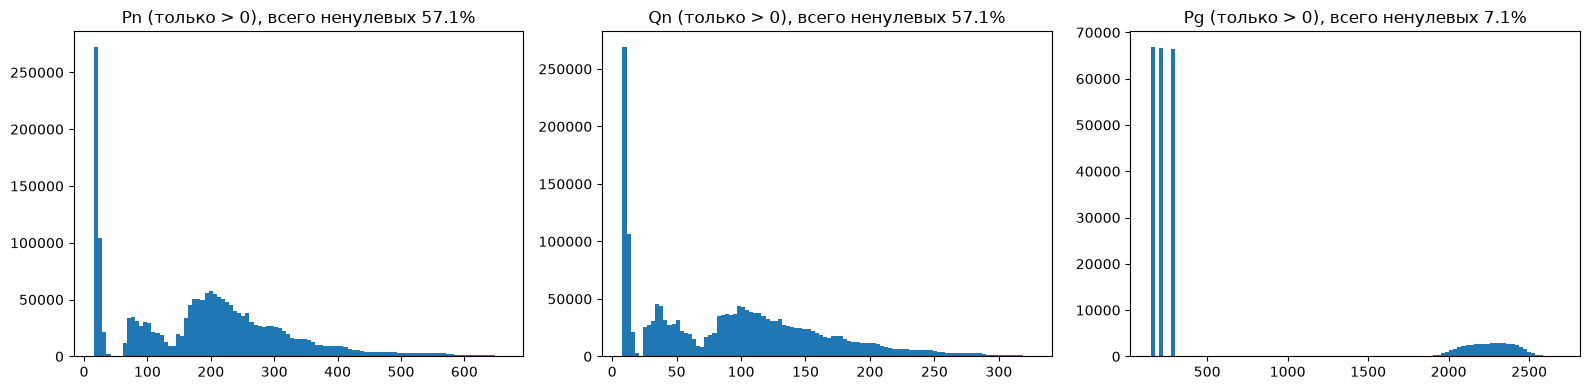

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, c in zip(axes, ["Pn", "Qn", "Pg"]):
    x = nodes.loc[nodes[c] > 0, c]
    ax.hist(x, bins=100); ax.set_title(f"{c} (только > 0), всего ненулевых {len(x)/len(nodes):.1%}")
plt.tight_layout(); plt.show()

## 4. Сходящиеся vs несходящиеся режимы

valid,0,1
sumPn,4138.300781,3560.622559
sumQn,2062.209717,1777.978760
sumPg,449.325378,2701.377686
maxPn,534.026062,425.515198
maxPg,258.056183,2251.289062
n_load,20.000000,20.000000
n_gen,2.000000,3.000000
balance,-3688.975342,-859.244873


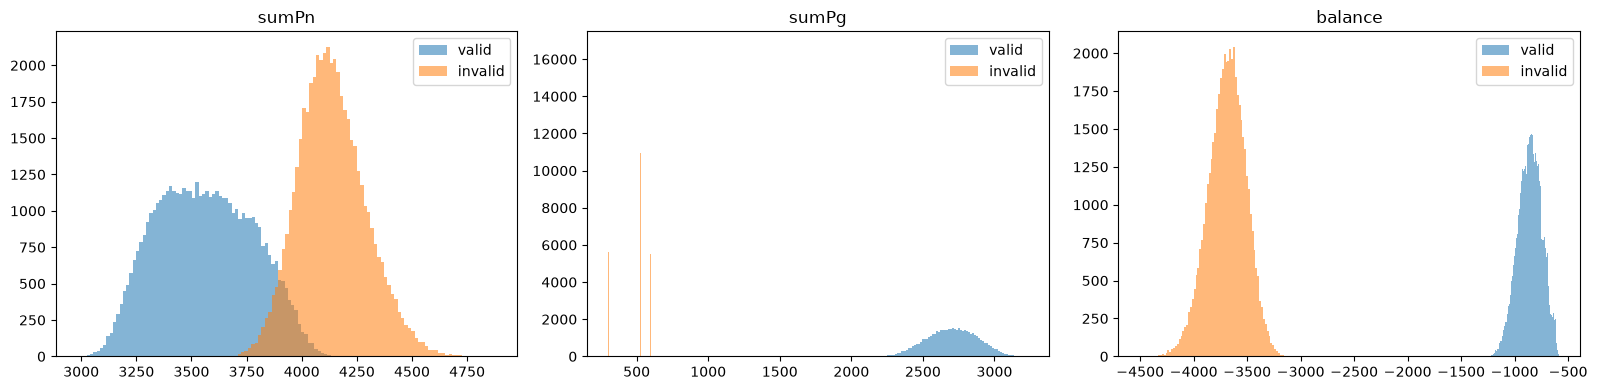

In [13]:
agg = nodes.groupby("exp").agg(valid=("valid", "max"), sumPn=("Pn", "sum"), sumQn=("Qn", "sum"),
                               sumPg=("Pg", "sum"), maxPn=("Pn", "max"), maxPg=("Pg", "max"),
                               n_load=("Pn", lambda s: (s > 0).sum()), n_gen=("Pg", lambda s: (s > 0).sum()))
agg["balance"] = agg["sumPg"] - agg["sumPn"]
display(agg.groupby("valid").mean().T)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, c in zip(axes, ["sumPn", "sumPg", "balance"]):
    for v, lab in [(1, "valid"), (0, "invalid")]:
        ax.hist(agg.loc[agg["valid"] == v, c], bins=80, alpha=0.55, label=lab)
    ax.set_title(c); ax.legend()
plt.tight_layout(); plt.show()

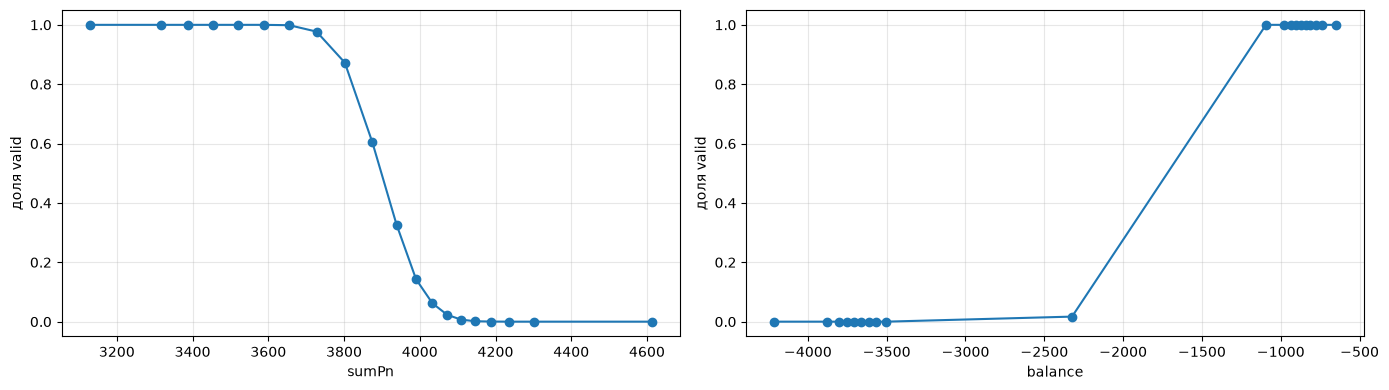

In [14]:
# Доля сходящихся режимов в зависимости от суммарной нагрузки / небаланса
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, c in zip(axes, ["sumPn", "balance"]):
    bins = pd.qcut(agg[c], 20, duplicates="drop")
    rate = agg.groupby(bins, observed=True)["valid"].mean()
    ax.plot([iv.mid for iv in rate.index], rate.values, "o-")
    ax.set_xlabel(c); ax.set_ylabel("доля valid"); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

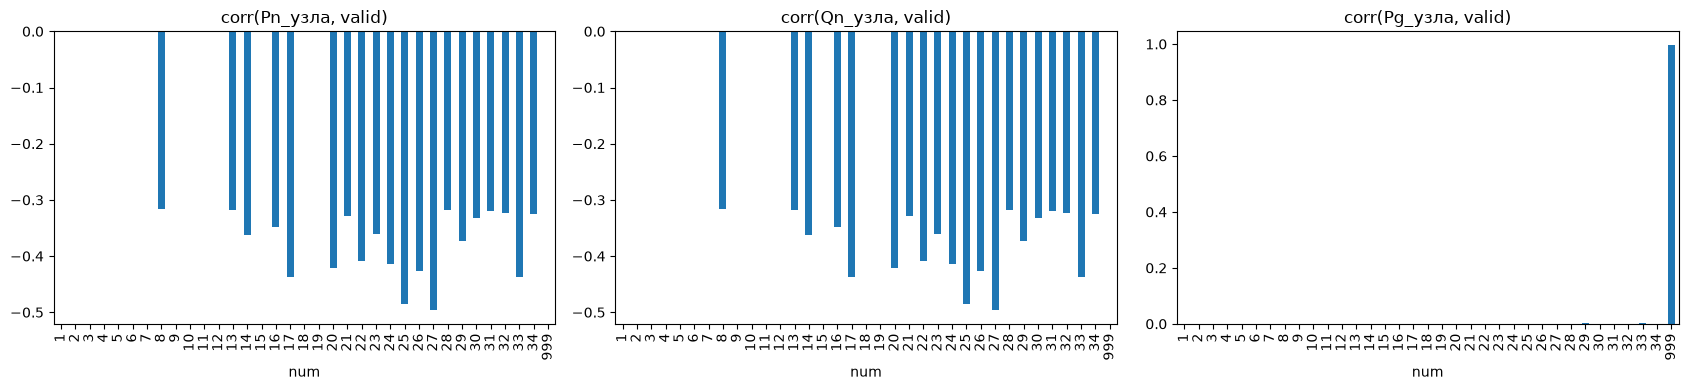

In [15]:
# Корреляция нагрузки/генерации в КАЖДОМ узле с флагом сходимости
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, c in zip(axes, ["Pn", "Qn", "Pg"]):
    P = nodes.pivot(index="exp", columns="num", values=c).reindex(reg.index)
    P.corrwith(reg).plot.bar(ax=ax, title=f"corr({c}_узла, valid)")
plt.tight_layout(); plt.show()

## 5. Целевые переменные: V и Delta (только сходящиеся)

,count,mean,std,min,25%,50%,75%,max
U,,,,,,,,
110.0,751275.0,0.852040,0.070637,0.509527,0.808818,0.859700,0.902864,1.006127
220.0,601020.0,0.923768,0.096428,0.546082,0.856936,0.915373,1.023217,1.062355
500.0,400680.0,0.991768,0.047537,0.786960,0.968022,1.020000,1.020000,1.020000


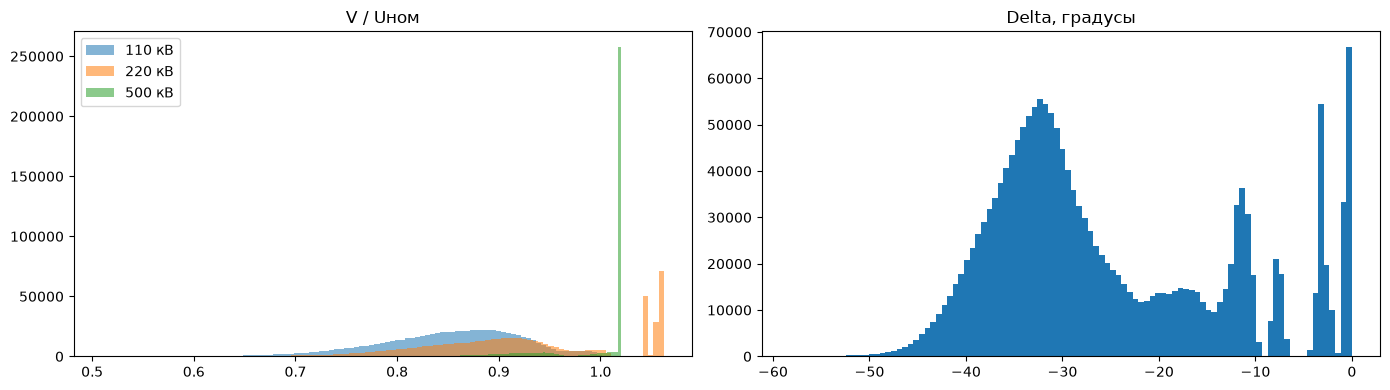

Диапазон V/Uном по режимам (мин/макс по узлам):


,min,max
count,50085.000000,50085.000000
mean,0.765108,1.062279
std,0.067776,0.000050
min,0.509527,1.062077
25%,0.724473,1.062245
50%,0.779245,1.062286
75%,0.818045,1.062318
max,0.883618,1.062355


In [16]:
nv = nodes_v.assign(Vrel=nodes_v["V"] / nodes_v["U"])
display(nv.groupby("U")["Vrel"].describe())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for u in sorted(nv["U"].unique()):
    axes[0].hist(nv.loc[nv["U"] == u, "Vrel"], bins=100, alpha=0.55, label=f"{u:g} кВ")
axes[0].set_title("V / Uном"); axes[0].legend()
axes[1].hist(nv["Delta"], bins=100); axes[1].set_title("Delta, градусы")
plt.tight_layout(); plt.show()

print("Диапазон V/Uном по режимам (мин/макс по узлам):")
display(nv.groupby("exp")["Vrel"].agg(["min", "max"]).describe())

In [17]:
# Насколько V и Delta зависят от суммарной нагрузки: корреляции по узлам
tmp = nv.merge(agg[["sumPn", "sumQn", "sumPg"]], left_on="exp", right_index=True)
cor = tmp.groupby("num").apply(lambda d: pd.Series({
    "corr(Vrel,sumPn)": d["Vrel"].corr(d["sumPn"]),
    "corr(Delta,sumPn)": d["Delta"].corr(d["sumPn"]),
    "corr(Delta,sumPg)": d["Delta"].corr(d["sumPg"])}))
display(cor.round(2))

,"corr(Vrel,sumPn)","corr(Delta,sumPn)","corr(Delta,sumPg)"
num,,,
1,-0.09,-0.99,-0.85
2,NaN,-0.99,-0.85
3,-0.96,-1.00,-0.86
4,NaN,-0.99,-0.85
5,-0.96,-0.99,-0.84
6,-0.96,-0.99,-0.84
7,NaN,-0.99,-0.85
8,-0.89,-0.98,-0.85
9,-0.95,-0.99,-0.85


## 6. Линии: топология и токи

In [18]:
params = ["Ns", "Ne", "type", "R", "X", "B", "Kt", "Idop"]
var = lines.groupby("num")[params].nunique()
changing = var.loc[(var > 1).any(axis=1)]
print(f"Линий (уникальных номеров): {lines['num'].nunique()}")
print("Параметры линии МЕНЯЮТСЯ между режимами у линий:", len(changing), "(0 = топология фиксирована)")
if len(changing):
    display(changing.head(20))

first = lines[lines["exp"] == lines["exp"].min()].set_index("num")
display(first[["Ns", "Ne", "type", "R", "X", "B", "Kt", "Idop", "Imax", "Izarg"]])

Линий (уникальных номеров): 80
Параметры линии МЕНЯЮТСЯ между режимами у линий: 80 (0 = топология фиксирована)


,Ns,Ne,type,R,X,B,Kt,Idop
num,,,,,,,,
1,1,1,1,1,1,1,1,84
2,1,1,1,1,1,1,1,111
3,1,1,1,1,1,1,1,15
4,1,1,1,1,1,1,1,9
5,1,1,1,1,1,1,1,17
6,1,1,1,1,1,1,1,13
7,1,1,1,1,1,1,1,15
8,1,1,1,1,1,1,1,140
9,1,1,1,1,1,1,1,140


,Ns,Ne,type,R,X,B,Kt,Idop,Imax,Izarg
num,,,,,,,,,,
1,999,3,0,2.96,45.599998,-546.799988,0.000,3003.100098,1177.199951,39.200001
2,999,4,0,1.18,18.240000,-218.699997,0.000,3003.100098,876.900024,29.200001
3,15,16,0,1.10,6.300000,-40.500000,0.000,824.900024,632.700012,76.699997
4,16,22,1,0.57,29.090000,18.799999,0.505,478.700012,382.000000,79.800003
5,10,15,0,1.46,8.400000,-54.000000,0.000,825.000000,557.700012,67.599998
...,...,...,...,...,...,...,...,...,...,...
76,25,33,0,0.48,2.150000,-13.200000,0.000,709.400024,197.199997,27.799999
77,22,29,0,4.80,21.450001,-132.300003,0.000,709.500000,172.399994,24.299999
78,23,29,0,1.92,8.580000,-52.900002,0.000,710.799988,157.800003,22.200001


In [19]:
print("Типы ветвей:\n", first["type"].value_counts())
print("\nKt по типам:\n", first.groupby("type")["Kt"].unique())
print("\nЛинии, связанные с узлами 999 / 0 (не из таблицы узлов):")
display(first[first[["Ns", "Ne"]].isin([999, 0]).any(axis=1)][["Ns", "Ne", "type", "R", "X", "Idop"]])

Типы ветвей:
 type
0    56
1    24
Name: count, dtype: int64

Kt по типам:
 type
0            [0.0]
1    [0.505, 0.46]
Name: Kt, dtype: object

Линии, связанные с узлами 999 / 0 (не из таблицы узлов):


,Ns,Ne,type,R,X,Idop
num,,,,,,
1,999,3,0,2.96,45.599998,3003.100098
2,999,4,0,1.18,18.240000,3003.100098
51,999,7,0,11.82,182.399994,2992.199951
55,999,12,1,0.57,35.889999,882.799988
56,999,12,1,0.57,35.889999,882.799988


Imax/Idop*100 - Izarg:
count    4.006800e+06
mean    -9.653374e-07
std      2.555567e-03
min     -2.729797e-02
25%     -9.441376e-04
50%      0.000000e+00
75%      9.460449e-04
max      2.685547e-02
dtype: float64


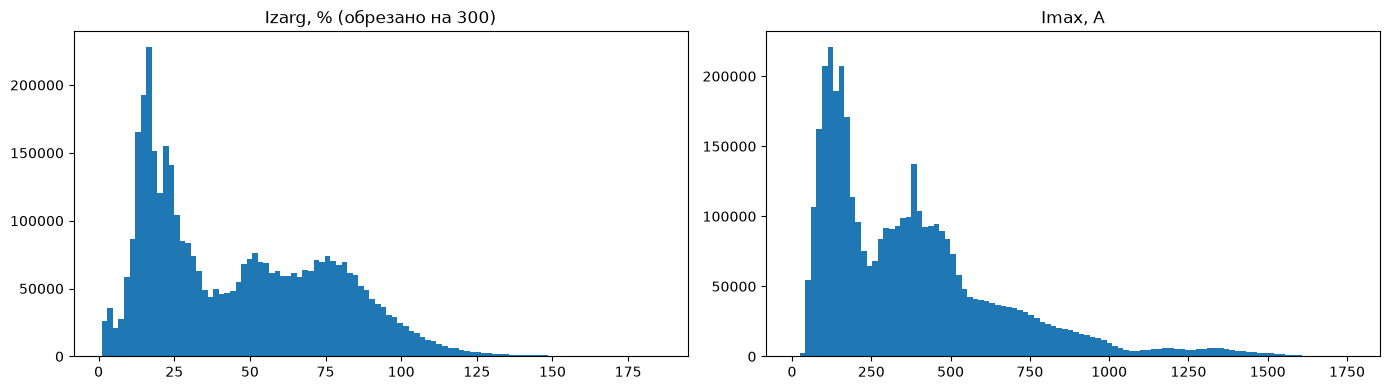

Доля сходящихся режимов, где хоть одна линия перегружена (Izarg > 100): 0.845


Imax                              Izarg                  
            mean        std          max       mean   std         max
num                                                                  
1    1237.900024  76.099998  1462.500000  41.299999   2.5   48.700001
2     918.000000  56.900002  1073.099976  30.600000   1.9   35.799999
3     662.599976  72.599998  1006.099976  80.300003   8.8  122.000000
4     406.600006  54.700001   666.000000  84.900002  11.4  139.000000
5     579.799988  68.000000   938.299988  70.300003   8.2  113.699997
..           ...        ...          ...        ...   ...         ...
76    155.699997  35.900002   347.500000  21.900000   5.1   48.900002
77    192.399994  33.099998   332.299988  27.100000   4.7   46.799999
78    166.000000   9.500000   231.699997  23.400000   1.3   32.599998
79    303.200012  40.299999   485.399994  59.500000   7.9   95.199997
80    361.100006  44.299999   555.000000  70.800003   8.7  108.800003

[80 rows x 6 columns]

In [20]:
lv = lines_v.copy()
# Проверка формулы Izarg = Imax / Idop * 100
err = (lv["Imax"] / lv["Idop"] * 100 - lv["Izarg"])
print("Imax/Idop*100 - Izarg:"); print(err.describe())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(lv["Izarg"].clip(upper=300), bins=100); axes[0].set_title("Izarg, % (обрезано на 300)")
axes[1].hist(lv["Imax"], bins=100); axes[1].set_title("Imax, A")
plt.tight_layout(); plt.show()

print("Доля сходящихся режимов, где хоть одна линия перегружена (Izarg > 100):",
      (lv.groupby("exp")["Izarg"].max() > 100).mean().round(3))
display(lv.groupby("num")[["Imax", "Izarg"]].agg(["mean", "std", "max"]).round(1))

## 7. Физическая проверка: можно ли восстановить ток из V и Delta?

Грубая проверка гипотезы «ток = закон Ома по предсказанным V и Delta». Считаем ток по продольной ветви
(без поперечной проводимости B) для обычных линий (Kt = 0) между узлами из таблицы узлов.
Единицы предполагаются: R, X в Ом, V в кВ (линейное), ток в А.
Если ratio ≈ 1 и корреляция высокая, токи надо считать физикой. Иначе смотреть единицы, влияние B, Kt.

линий для проверки: 168000
corr(I_calc, Imax): 0.9953
ratio I_calc/Imax:
count    168000.000000
mean          0.962169
std           0.101613
min           0.047012
25%           0.981225
50%           0.995031
75%           0.998176
max           1.004235
Name: ratio, dtype: float64


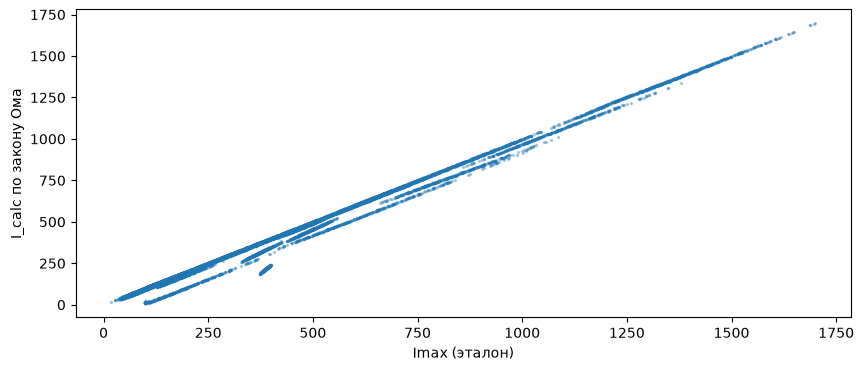

In [21]:
rng = np.random.default_rng(0)
ids = rng.choice(reg[reg == 1].index.values, size=min(3000, int(reg.sum())), replace=False)
L = lines_v[lines_v["exp"].isin(ids) & (lines_v["Kt"] == 0)]
N = nodes_v.loc[nodes_v["exp"].isin(ids), ["exp", "num", "V", "Delta"]]
for side in ("Ns", "Ne"):
    L = L.merge(N.rename(columns={"num": side, "V": f"V_{side}", "Delta": f"D_{side}"}),
                on=["exp", side], how="inner")
print("линий для проверки:", len(L))

Vs = L["V_Ns"].values * np.exp(1j * np.deg2rad(L["D_Ns"].values))
Ve = L["V_Ne"].values * np.exp(1j * np.deg2rad(L["D_Ne"].values))
Z = (L["R"].values + 1j * L["X"].values)
L["I_calc"] = np.abs(Vs - Ve) / (np.sqrt(3) * np.abs(Z)) * 1000

L["ratio"] = L["I_calc"] / L["Imax"].replace(0, np.nan)
print("corr(I_calc, Imax):", L["I_calc"].corr(L["Imax"]).round(4))
print("ratio I_calc/Imax:"); print(L["ratio"].describe())
plt.scatter(L["Imax"][:20000], L["I_calc"][:20000], s=2, alpha=.3)
plt.xlabel("Imax (эталон)"); plt.ylabel("I_calc по закону Ома"); plt.show()

## 8. Бейзлайн организаторов на этих данных (опционально)

Нужны `baseline_solution.py` и `weights.joblib` рядом с ноутбуком. Модели, скорее всего, обучены на всём train,
поэтому метрики здесь **оптимистичны**: это проверка, что пайплайн работает, а не честная оценка.

In [22]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, f1_score

def reg_metrics(y, p):
    return {"MAE": mean_absolute_error(y, p), "RMSE": np.sqrt(mean_squared_error(y, p)), "R2": r2_score(y, p)}

BASELINE_PY, WEIGHTS = Path("baseline_solution.py"), Path("weights.joblib")
if BASELINE_PY.exists() and WEIGHTS.exists():
    import importlib.util
    try:                                   # нужно, если веса сохранены в другой версии sklearn
        import sklearn._loss._loss as _m; sys.modules.setdefault("_loss", _m)
    except Exception:
        pass
    spec = importlib.util.spec_from_file_location("baseline_solution", BASELINE_PY)
    bs = importlib.util.module_from_spec(spec); spec.loader.exec_module(bs)

    ids = np.random.default_rng(1).choice(reg.index.values, size=min(3000, len(reg)), replace=False)
    ns = nodes[nodes["exp"].isin(ids)].reset_index(drop=True)
    ls = lines[lines["exp"].isin(ids)].reset_index(drop=True)
    inv_n = {v: k for k, v in NODE_MAP.items()}; inv_l = {v: k for k, v in LINE_MAP.items()}
    # имитируем тест: без целевых столбцов
    raw_n = ns.drop(columns=["V", "Delta", "valid"]).rename(columns=inv_n)
    raw_l = ls.drop(columns=["Imax", "Izarg", "valid"]).rename(columns=inv_l)

    model = bs.PowerGridBaseline(WEIGHTS); model.load()
    pn, pl = model.predict(raw_n, raw_l)

    m = ns["valid"].values == 1
    res = {"V": reg_metrics(ns["V"][m], pn["V"].values[m]),
           "Delta": reg_metrics(ns["Delta"][m], pn["Delta"].values[m])}
    ml = ls["valid"].values == 1
    res["Imax"] = reg_metrics(ls["Imax"][ml], pl["Imax, A"].values[ml])
    res["Izarg"] = reg_metrics(ls["Izarg"][ml], pl["Izarg, %"].values[ml])
    display(pd.DataFrame(res).T)

    truth = ns.groupby("exp")["valid"].max()
    pred = pn.groupby("ID_опыта")["Regime_valid"].max().reindex(truth.index)
    print("F1-macro (regime_valid):", round(f1_score(truth, pred, average="macro"), 4))
else:
    print("baseline_solution.py / weights.joblib не найдены, ячейка пропущена")

ModuleNotFoundError: No module named 'sklearn'

In [23]:
Pn = nodes.pivot(index="ID_опыта", columns="Номер", values="P_н")
print((Pn.max() > 0).sum())            # должно быть 20
print(Pn.columns[Pn.max() > 0].tolist())  # номера этих узлов

KeyError: "The following 'columns' labels are not columns of the DataFrame: ['Номер']"

## Что смотреть в выводах

- **Раздел 1–2:** одинаковое число узлов/линий в каждом режиме, нет пропусков, флаг един внутри режима, что лежит в V/Delta/токах у invalid.
- **Раздел 3:** какие узлы фиксируют V (PV/балансирующие), какие несут нагрузку, где генерация.
- **Раздел 4:** какие признаки (суммарная нагрузка, небаланс, нагрузка конкретных узлов) отделяют несходящиеся режимы. Это основа признаков классификатора.
- **Раздел 6:** фиксирована ли топология (если да, MLP/бустинг достаточно, GNN не обязателен); связь с узлами 999 и 0.
- **Раздел 7:** воспроизводятся ли токи по закону Ома, тогда их лучше считать из V и Delta.